In [1]:
library(ggrepel)
setwd('../intmd/sc-K562-1e4_to_tradeSeq/')

Loading required package: ggplot2



In [4]:
plot_association_volcano <- function(
  asso_df,
  # ---------- thresholds ----------
  fdr_thresh        = 0.01,
  require_fdr       = TRUE,     # if FALSE, do not gate "specific" by qval
  dyn_thresh_k562   = 0.75,
  flat_thresh_k562  = 0.25,
  dyn_thresh_thp1   = 0.75,
  flat_thresh_thp1  = 0.25,

  # ---------- plotting ----------
  point_alpha       = 0.95,
  point_size        = 2.2,
  axis_title_size   = 26,
  axis_text_size    = 18,
  legend_text_size  = 16,
  axis_title_pad_x  = 12,
  axis_title_pad_y  = 12,
  y_log_floor       = 1e-6,
  x_lim             = NULL,
  y_lim             = NULL,
  y_break           = NULL,
  y_break_quantile  = 0.95,
  y_lower_scale     = 0.35,

  # ---------- labels ----------
  top_labels        = 12,
  label_size        = 4.6,
  label_only_pass   = FALSE,
  label_rank_by     = c("wald","x"),
  label_top_wald    = NULL,
  label_top_k562    = NULL,
  label_top_thp1    = NULL,

  # ggrepel controls
  repel_box_padding   = 0.25,
  repel_point_padding = 0.20,
  repel_min_segment_length = 0,
  repel_force         = 1.2,
  repel_max_overlaps  = Inf,
  repel_seed          = 1,

  # ---------- legend labels & colors ----------
  lab_k562_ind      = "K562-I induction",
  lab_k562_rep      = "K562-I repression",
  lab_thp1_ind      = "K562-E induction",
  lab_thp1_rep      = "K562-E repression",

  col_k562_ind      = "#1F4E79",
  col_k562_rep      = "#CFE2F3",
  col_thp1_ind      = "#C00000",
  col_thp1_rep      = "#F4CCCC",

  col_sigmid        = "#6E6E6E",
  col_other         = "#B8B8B8",
  col_line          = "#6E6E6E",

  # NEW: legend placement inside plot (0..1 panel coords)
  legend_pos        = c(0.03, 0.05),  # bottom-left
  legend_just       = c(0, 0),        # anchor at its bottom-left
  legend_bg_alpha   = 0.75,           # semi-transparent box
  legend_bg_col     = "white",
  legend_key_size   = 0.8,            # in lines

  save_prefix       = NULL
) {
  label_rank_by <- match.arg(label_rank_by)
  stopifnot(all(c("waldStat_1","waldStat_2","qval","log2FC_t1","log2FC_t2") %in% names(asso_df)))
  df <- asso_df

  # ---- require ggrepel ----
  if (!requireNamespace("ggrepel", quietly = TRUE)) {
    stop("Package 'ggrepel' is required. Install via install.packages('ggrepel').")
  }

  # ---------- mapping (CRITICAL) ----------
  # Your convention: t1 = K562-Imm, t2 = K562-Ery
  k562_eff <- as.numeric(df$log2FC_t1)
  thp1_eff <- as.numeric(df$log2FC_t2)

  # x: magnitude difference (right = K562-Imm more dynamic)
  x_raw <- abs(k562_eff) - abs(thp1_eff)

  # y: max Wald
  y_raw <- pmax(df$waldStat_1, df$waldStat_2, na.rm = TRUE)
  y_raw[!is.finite(y_raw)] <- NA_real_

  q_raw <- as.numeric(df$qval)
  pass_fdr  <- is.finite(q_raw) & (q_raw < fdr_thresh)
  pass_gate <- if (isTRUE(require_fdr)) pass_fdr else rep(TRUE, nrow(df))

  # clamp y for plotting
  y_plot <- ifelse(is.finite(y_raw), pmax(y_raw, y_log_floor), y_log_floor)
  if (!is.null(y_lim) && length(y_lim) == 2) {
    if (is.finite(y_lim[1])) y_plot <- pmax(y_plot, max(y_log_floor, y_lim[1]))
    if (is.finite(y_lim[2])) y_plot <- pmin(y_plot, y_lim[2])
  }

  # clamp x for plotting
  x_plot <- x_raw
  if (!is.null(x_lim) && length(x_lim) == 2 && all(is.finite(x_lim))) {
    xmin <- min(x_lim); xmax <- max(x_lim)
    msk  <- is.finite(x_plot)
    x_plot[msk] <- pmin(pmax(x_plot[msk], xmin), xmax)
  }

  df$x_plot <- x_plot
  df$y_plot <- y_plot

  # ---------- specificity + direction ----------
  k_dyn  <- is.finite(k562_eff) & (abs(k562_eff) >= dyn_thresh_k562)
  k_flat <- is.finite(k562_eff) & (abs(k562_eff) <= flat_thresh_k562)
  t_dyn  <- is.finite(thp1_eff) & (abs(thp1_eff) >= dyn_thresh_thp1)
  t_flat <- is.finite(thp1_eff) & (abs(thp1_eff) <= flat_thresh_thp1)

  k562_spec <- pass_gate & k_dyn & t_flat
  thp1_spec <- pass_gate & t_dyn & k_flat

  k_pos <- is.finite(k562_eff) & (k562_eff > 0)
  k_neg <- is.finite(k562_eff) & (k562_eff < 0)
  t_pos <- is.finite(thp1_eff) & (thp1_eff > 0)
  t_neg <- is.finite(thp1_eff) & (thp1_eff < 0)

  side <- rep("other", nrow(df))
  side[pass_fdr] <- "sig_mid"  # significant but not specific

  side[k562_spec & k_pos] <- "k562_ind"
  side[k562_spec & k_neg] <- "k562_rep"
  side[thp1_spec & t_pos] <- "thp1_ind"
  side[thp1_spec & t_neg] <- "thp1_rep"

  df$side <- factor(side, levels = c("other","sig_mid","k562_ind","k562_rep","thp1_ind","thp1_rep"))

  # ---------- label selection ----------
  df$label <- ""
  rn <- rownames(df)
  gene_names <- if (!is.null(rn)) rn else if ("gene" %in% names(df)) as.character(df$gene) else as.character(seq_len(nrow(df)))

  pass_side <- if (label_only_pass) df$side %in% c("k562_ind","k562_rep","thp1_ind","thp1_rep") else rep(TRUE, nrow(df))

  labs_idx <- integer(0)

  if (!is.null(label_top_wald) && as.integer(label_top_wald) > 0) {
    cand <- which(is.finite(y_raw) & pass_side)
    if (length(cand)) {
      ord <- cand[order(y_raw[cand], abs(x_raw[cand]), decreasing = TRUE)]
      labs_idx <- c(labs_idx, head(ord, as.integer(label_top_wald)))
    }
  }

  if (!is.null(label_top_k562) && as.integer(label_top_k562) > 0) {
    cand <- which(df$side %in% c("k562_ind","k562_rep") & pass_side & is.finite(k562_eff) & is.finite(y_raw))
    if (length(cand)) {
      ord <- cand[order(abs(k562_eff[cand]), y_raw[cand], decreasing = TRUE)]
      labs_idx <- c(labs_idx, head(ord, as.integer(label_top_k562)))
    }
  }

  if (!is.null(label_top_thp1) && as.integer(label_top_thp1) > 0) {
    cand <- which(df$side %in% c("thp1_ind","thp1_rep") & pass_side & is.finite(thp1_eff) & is.finite(y_raw))
    if (length(cand)) {
      ord <- cand[order(abs(thp1_eff[cand]), y_raw[cand], decreasing = TRUE)]
      labs_idx <- c(labs_idx, head(ord, as.integer(label_top_thp1)))
    }
  }

  if (length(labs_idx) == 0 && top_labels > 0) {
    rank_val <- if (label_rank_by == "wald") y_raw else x_raw
    cand <- which(is.finite(rank_val) & pass_side)
    if (length(cand)) {
      ord <- cand[order(rank_val[cand], y_raw[cand], decreasing = TRUE)]
      labs_idx <- head(ord, as.integer(top_labels))
    }
  }

  labs_idx <- unique(labs_idx)
  df$label[labs_idx] <- gene_names[labs_idx]
  label_df <- df[df$label != "" & is.finite(df$x_plot) & is.finite(df$y_plot), , drop = FALSE]

  # ---------- piecewise scaling for y (log10) ----------
  logy <- log10(df$y_plot)
  if (is.null(y_break) || !is.finite(y_break)) {
    non_sig <- df$y_plot[!pass_fdr & is.finite(df$y_plot)]
    y_break <- if (length(non_sig)) as.numeric(stats::quantile(non_sig, probs = y_break_quantile, na.rm = TRUE))
    else as.numeric(stats::quantile(df$y_plot, probs = 0.60, na.rm = TRUE))
  }
  y_break <- max(y_break, y_log_floor)
  t_break <- log10(y_break)
  y_lower_scale <- max(1e-6, min(1, y_lower_scale))
  ps <- function(t) ifelse(t <= t_break, y_lower_scale * t, y_lower_scale * t_break + (t - t_break))
  df$y_scaled <- ps(log10(df$y_plot))

  t_lo <- if (!is.null(y_lim) && is.finite(y_lim[1])) log10(max(y_log_floor, y_lim[1])) else min(logy[is.finite(logy)])
  t_hi <- if (!is.null(y_lim) && is.finite(y_lim[2])) log10(y_lim[2])                 else max(logy[is.finite(logy)])
  y_limits_scaled <- ps(c(t_lo, t_hi))
  tick_t   <- seq(floor(t_lo), ceiling(t_hi), by = 1)
  tick_pos <- ps(tick_t)
  tick_lab <- as.character(tick_t)

  df$y_scaled <- ps(log10(df$y_plot))
  label_df$y_scaled <- ps(log10(label_df$y_plot))

  # ---------- colors ----------
  col_map <- c(
    other    = col_other,
    sig_mid  = col_sigmid,
    k562_ind = col_k562_ind,
    k562_rep = col_k562_rep,
    thp1_ind = col_thp1_ind,
    thp1_rep = col_thp1_rep
  )

  # ---------- plot ----------
  p <- ggplot2::ggplot(df, ggplot2::aes(x = x_plot, y = y_scaled)) +
    ggplot2::geom_point(
      ggplot2::aes(colour = side),
      shape = 16, alpha = point_alpha, size = point_size, show.legend = TRUE
    ) +
    ggplot2::scale_colour_manual(
      values = col_map,
      breaks = c("k562_ind","k562_rep","thp1_ind","thp1_rep"),
      labels = c(lab_k562_ind, lab_k562_rep, lab_thp1_ind, lab_thp1_rep),
      drop   = FALSE,
      name   = NULL
    ) +
    ggplot2::geom_vline(xintercept = 0, linetype = "solid", size = 0.6, color = col_line) +
    ggplot2::scale_x_continuous(limits = if (!is.null(x_lim) && length(x_lim)==2) c(min(x_lim), max(x_lim)) else NULL) +
    ggplot2::scale_y_continuous(limits = y_limits_scaled, breaks = tick_pos, labels = tick_lab) +
    ggplot2::labs(
      x = expression("Response specificity (|log2fc(K562-I)| - |log2fc(K562-E)|)"),
      y = expression(log[10]("Wald"))
    ) +
    ggplot2::theme_classic(base_size = 20) +
    ggplot2::theme(
      panel.grid.major.y = ggplot2::element_line(color = "grey85", linewidth = 0.4),
      panel.grid.minor.y = ggplot2::element_blank(),
      axis.title.x       = ggplot2::element_text(
                             size = axis_title_size,
                             margin = ggplot2::margin(t = axis_title_pad_x)
                           ),
      axis.title.y       = ggplot2::element_text(
                             size = axis_title_size, face = "bold",
                             margin = ggplot2::margin(r = axis_title_pad_y)
                           ),
      axis.text          = ggplot2::element_text(size = axis_text_size),
      plot.margin        = ggplot2::margin(14, 18, 14, 16),

      # --------- UPDATED: legend inside bottom-left ----------
      legend.position    = legend_pos,
      legend.justification = legend_just,
      legend.background  = ggplot2::element_rect(
                             fill = scales::alpha(legend_bg_col, legend_bg_alpha),
                             color = "grey60",
                             linewidth = 0.3
                           ),
      legend.key         = ggplot2::element_rect(fill = NA, color = NA),
      legend.key.size    = ggplot2::unit(legend_key_size, "lines"),
      legend.text        = ggplot2::element_text(size = legend_text_size)
    )

  # ---------- ggrepel labels ----------
  if (nrow(label_df) > 0) {
    p <- p +
      ggrepel::geom_label_repel(
        data = label_df,
        ggplot2::aes(x = x_plot, y = y_scaled, label = label),
        inherit.aes = FALSE,
        size = label_size,
        label.size = 0.15,
        label.padding = ggplot2::unit(0.10, "lines"),
        fill = scales::alpha("white", 0.75),
        color = "black",
        box.padding = ggplot2::unit(repel_box_padding, "lines"),
        point.padding = ggplot2::unit(repel_point_padding, "lines"),
        min.segment.length = repel_min_segment_length,
        force = repel_force,
        max.overlaps = repel_max_overlaps,
        seed = repel_seed
      )
  }

  if (!is.null(save_prefix)) {
    ggplot2::ggsave(paste0(save_prefix, ".png"), p, width = 10, height = 8.75, dpi = 300)
    ggplot2::ggsave(paste0(save_prefix, ".pdf"), p, width = 10, height = 8.75, dpi = 300)
  }

  p
}

In [2]:
combined = readRDS('combined.rds')
combined = combined[!is.na(combined$waldStat),]
dim(combined)
sum(is.na(combined$df))

[1] 13855    25

[1] 0

In [3]:
combined = combined[(combined$pvalue < 0.05) | (combined$pvalue_1 < 0.05) | (combined$pvalue_2 < 0.05),]
dim(combined)
sum(is.na(combined$df))

[1] 1636   25

[1] 4

Warning message:
"Removed 4 rows containing missing values or values outside the scale range
(`geom_point()`)."


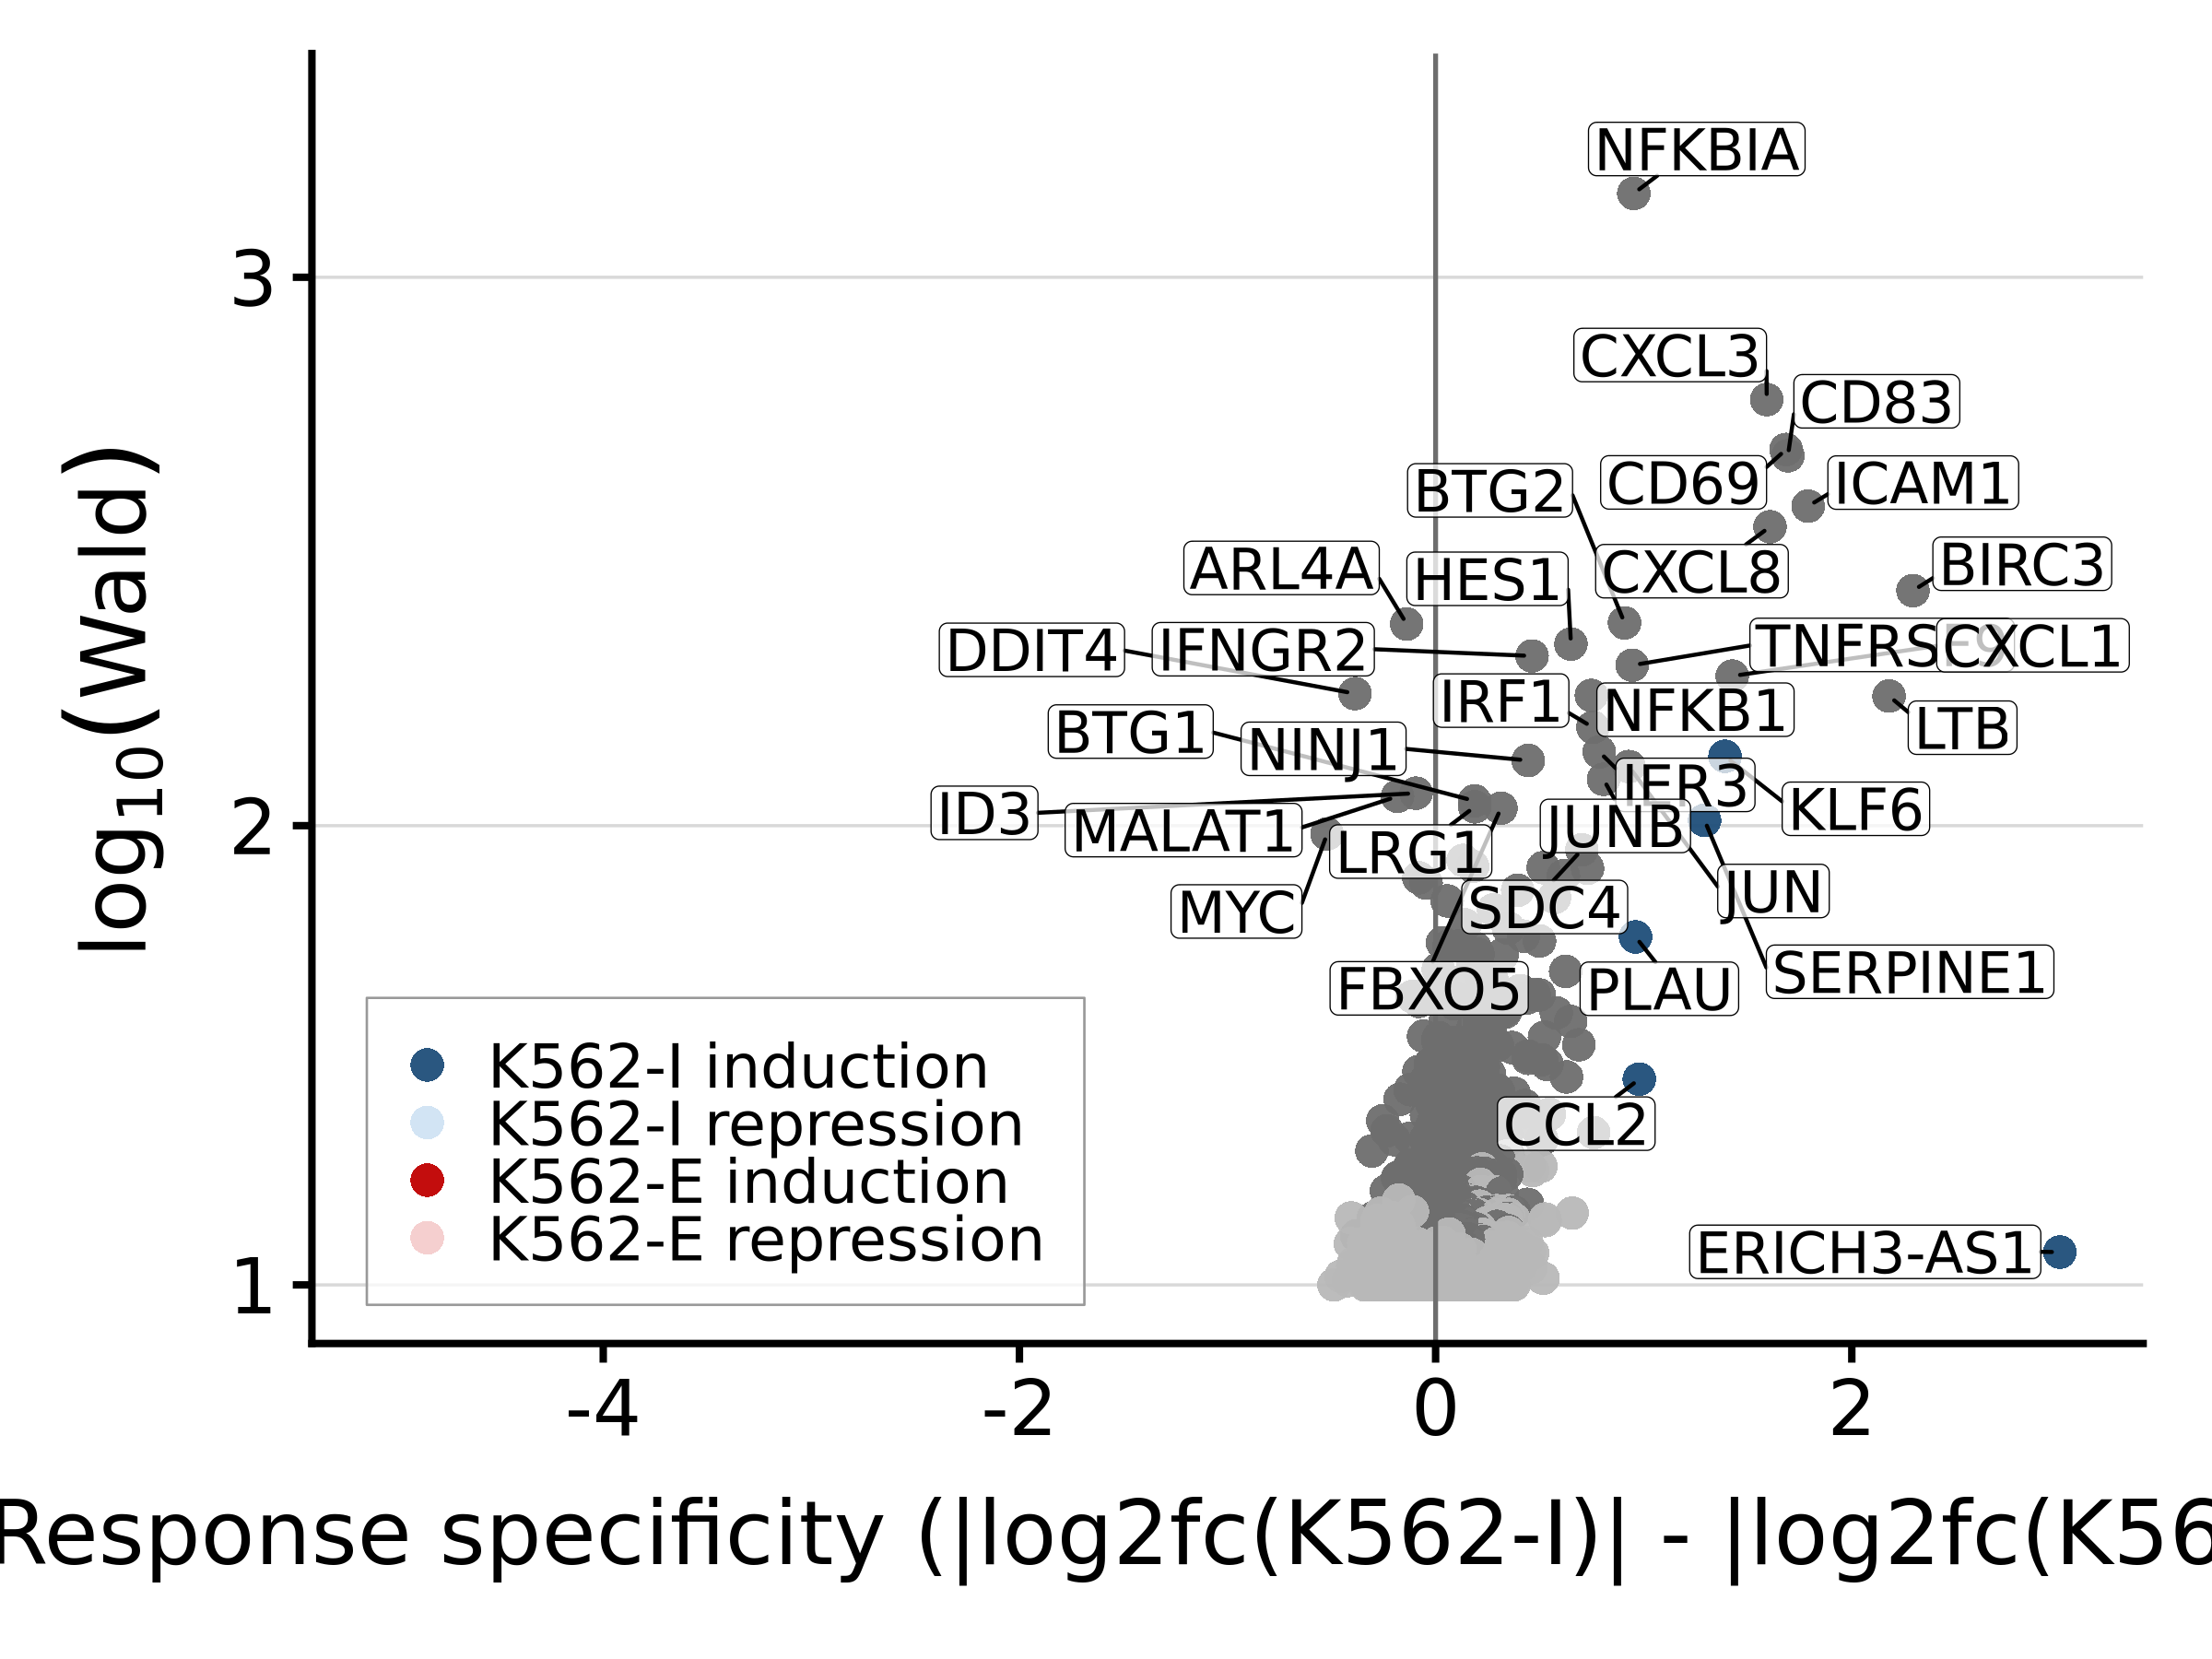

In [7]:
# options(repr.plot.width = 10, repr.plot.height = 8.75, repr.plot.res = 300)
options(repr.plot.width = 8, repr.plot.height = 6, repr.plot.res = 300)

dyn_thresh  <- 1
flat_thresh <- 0.5

p <- plot_association_volcano(
  combined,
  require_fdr      = FALSE,  # set TRUE for strict gating
  fdr_thresh       = 0.01,
  dyn_thresh_k562  = dyn_thresh,
  flat_thresh_thp1 = flat_thresh,
  dyn_thresh_thp1  = dyn_thresh,
  flat_thresh_k562 = flat_thresh,
  x_lim = c(-5, 3),
  y_lim = c(10, 2000),
  label_top_wald = 30,
  label_top_k562 = 30,
  label_top_thp1 = 30,
  label_size = 5.2,
  axis_title_size = 23,
  axis_text_size  = 20,
  legend_text_size = 16,
  point_size = 3.5,
  # legend placement inside bottom-left
  legend_pos  = c(0.03, 0.03),
  legend_just = c(0, 0),
  # ggrepel tuning
  repel_force = 1.4,
  repel_box_padding = 0.25,
  repel_point_padding = 0.10,
  repel_max_overlaps = Inf,
  repel_seed = 7,
  save_prefix = NULL
)
p